# T38 -- Phase 3: uncertainty / bootstrap stability layer on real T37 clusters

Adds descriptive uncertainty/stability measures on top of the already-computed,
already-approved T37 spatial clusters. **This notebook does not change T29-T37's
ranking logic** -- it reuses T36 `SourceScore`/T37 `CandidateCluster` outputs exactly
as already computed (Sections 1-3 below reproduce T37's own real-data setup, unchanged).

`source_score` remains an evidence-ranking score, NOT a probability. Bootstrap
`candidate_stability_percent` (if computed) is candidate/ranking STABILITY under
resampling, NOT a probability that a cluster is the true physical source.

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.particle_query import query_particle_slice
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_composite import DEFAULT_WEIGHTS, compute_source_scores_for_candidates
from iste.phase3_clustering import DEFAULT_EPS_M, cluster_candidates
from iste.phase3_uncertainty import (
    DEFAULT_TOTAL_TIMESTAMPS, DEFAULT_SPATIAL_PERCENTILE, BootstrapConfig,
    compute_cluster_uncertainty_table, compute_total_available_particles,
    diagnose_uncertainty_vs_age, run_bootstrap_stability,
)

## 1. Load real Stage III result + regenerate candidates with support grids (identical to T37)

In [2]:
history_path = os.path.join(REPO_ROOT, "results", "actual_data", "stage3_particle_history.npz")
cached = np.load(history_path, allow_pickle=True)

def _none_if_empty(arr):
    return None if arr.size == 0 else arr

records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
historical_timestamps = grid[1:]
print(f"loaded {records.n_records} real rows; {len(historical_timestamps)} historical timestamps; "
      f"full analysis grid (incl. T0) has {len(grid)} timestamps")

loaded 240024 real rows; 72 historical timestamps; full analysis grid (incl. T0) has 73 timestamps


In [3]:
spill_data = json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

t0 = time.time()
all_candidates = []
support_grids_by_t_s = {}
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(
        index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    grid_vals = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    support_grids_by_t_s[np.datetime64(t_s, "ns")] = grid_vals
    all_candidates.extend(find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config))
t1 = time.time()
print(f"regenerated {len(all_candidates)} real candidates in {t1-t0:.1f}s")

regenerated 280 real candidates in 61.7s


## 2. Compute T36 DEFAULT composite scores (reused, not recomputed differently)

In [4]:
t2 = time.time()
default_scores = compute_source_scores_for_candidates(
    records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M,
    weights=DEFAULT_WEIGHTS,
)
t3 = time.time()
print(f"computed T36 source scores for {len(default_scores)} real candidates in {t3-t2:.1f}s")

computed T36 source scores for 280 real candidates in 39.9s


## 3. Cluster the real candidates (T37, reused unchanged)

In [5]:
clusters = cluster_candidates(all_candidates, default_scores, eps_m=DEFAULT_EPS_M)
print(f"DEFAULT_EPS_M = {DEFAULT_EPS_M} m (reused from T31's spatial_matching_radius_m)")
print(f"{len(all_candidates)} raw candidates -> {len(clusters)} distinct spatial clusters")
n_members_total = sum(cl.n_members for cl in clusters)
assert n_members_total == len(all_candidates)
print(f"every candidate accounted for exactly once: confirmed ({n_members_total} == {len(all_candidates)})")

cluster_ids_before = [cl.cluster_id for cl in clusters]
members_before = {cl.cluster_id: tuple(cl.member_candidate_ids) for cl in clusters}
scores_before = {s.candidate_id: s.source_score for s in default_scores}

DEFAULT_EPS_M = 2000.0 m (reused from T31's spatial_matching_radius_m)
280 raw candidates -> 10 distinct spatial clusters
every candidate accounted for exactly once: confirmed (280 == 280)


## 4. T38 configuration used

All parameters below are explicit, documented, and configurable (see
`iste/phase3_uncertainty.py` module docstring for the full rationale of every default).

In [6]:
print(f"DEFAULT_TOTAL_TIMESTAMPS = {DEFAULT_TOTAL_TIMESTAMPS} (T27's own T0..T72 grid length)")
print(f"DEFAULT_SPATIAL_PERCENTILE = {DEFAULT_SPATIAL_PERCENTILE}")
total_available_particles = compute_total_available_particles(records)
print(f"total_available_particles (distinct (particle_id, forcing_member_id) pairs in records) = {total_available_particles}")

bootstrap_config = BootstrapConfig(n_replicates=200, random_seed=42, top_k=10)
print(f"bootstrap config: n_replicates={bootstrap_config.n_replicates}, "
      f"random_seed={bootstrap_config.random_seed}, top_k={bootstrap_config.top_k}")

DEFAULT_TOTAL_TIMESTAMPS = 73 (T27's own T0..T72 grid length)
DEFAULT_SPATIAL_PERCENTILE = 90.0
total_available_particles (distinct (particle_id, forcing_member_id) pairs in records) = 3288
bootstrap config: n_replicates=200, random_seed=42, top_k=10


## 5. Bootstrap practicality estimate + run

A full bootstrap (rebuilding the whole T16 support grid, i.e. re-running Section 1,
per replicate) measured tens of seconds for ONE pass above -- repeating that 100-200
times would cost many minutes to hours, and is explicitly avoided (see module
docstring). The PRACTICAL bootstrap implemented instead resamples each candidate's own
already-computed T16 neighborhood (cheap NumPy operations, no Stage III re-query, no
whole-grid recompute) -- timed directly below.

In [7]:
t4 = time.time()
bootstrap_result = run_bootstrap_stability(all_candidates, default_scores, clusters, config=bootstrap_config)
t5 = time.time()
print(f"bootstrap performed: {bootstrap_result.performed}")
print(f"reason: {bootstrap_result.reason}")
print(f"n_replicates_run: {bootstrap_result.n_replicates_run}")
print(f"measured runtime: {bootstrap_result.runtime_seconds:.2f}s (wall-clock re-check: {t5-t4:.2f}s)")

bootstrap performed: True
reason: bootstrap executed (see module docstring for scope/limitations)
n_replicates_run: 200
measured runtime: 2.88s (wall-clock re-check: 2.88s)


## 6. Confirm T36/T37 outputs are unchanged by T38

In [8]:
cluster_ids_after = [cl.cluster_id for cl in clusters]
members_after = {cl.cluster_id: tuple(cl.member_candidate_ids) for cl in clusters}
scores_after = {s.candidate_id: s.source_score for s in default_scores}
assert cluster_ids_after == cluster_ids_before, "T37 cluster IDs changed!"
assert members_after == members_before, "T37 cluster membership changed!"
assert scores_after == scores_before, "T36 source_score changed!"
print("T36 source_score values unchanged: confirmed")
print("T37 cluster IDs/membership unchanged: confirmed")

T36 source_score values unchanged: confirmed
T37 cluster IDs/membership unchanged: confirmed


## 7. Full T38 uncertainty table (Part G)

In [9]:
uncertainty_table = compute_cluster_uncertainty_table(
    clusters, all_candidates, default_scores, records,
    total_timestamps=DEFAULT_TOTAL_TIMESTAMPS, spatial_percentile=DEFAULT_SPATIAL_PERCENTILE,
    bootstrap_result=bootstrap_result,
)

rows = []
for row in uncertainty_table:
    rows.append(dict(
        cluster_id=row.cluster_id,
        centroid_lat=round(row.centroid_lat, 5), centroid_lon=round(row.centroid_lon, 5),
        spatial_radius_km=round(row.spatial_radius_km, 3),
        uncertainty_radius_km=round(row.uncertainty_radius_km, 3),
        temporal_uncertainty_hours=round(row.temporal_uncertainty_hours, 2),
        supporting_particle_count=row.supporting_particle_count,
        particle_support_fraction=round(row.particle_support_fraction, 5),
        supported_timestamp_count=row.supported_timestamp_count,
        persistence_fraction=round(row.persistence_fraction, 4),
        persistence_duration_hours=round(row.persistence_duration_hours, 1),
        mean_source_score=round(row.mean_source_score, 4),
        peak_source_score=round(row.peak_source_score, 4),
        candidate_stability_percent=(
            round(row.candidate_stability_percent, 1) if row.candidate_stability_percent is not None else "unavailable"
        ),
        ais_status=row.ais_status,
    ))
uncertainty_df = pd.DataFrame(rows)
print(uncertainty_df.to_string(index=False))

 cluster_id  centroid_lat  centroid_lon  spatial_radius_km  uncertainty_radius_km  temporal_uncertainty_hours  supporting_particle_count  particle_support_fraction  supported_timestamp_count  persistence_fraction  persistence_duration_hours  mean_source_score  peak_source_score  candidate_stability_percent  ais_status
cluster0000      34.25934      35.41014             24.439                 25.157                       20.76                       3015                    0.91697                         72                0.9863                        71.0             0.7429             1.4620                        100.0 unavailable
cluster0002      34.33003      35.34287             10.034                  8.423                        9.01                        377                    0.11466                         34                0.4658                        34.0             0.4116             0.7383                          0.0 unavailable
cluster0006      34.40575      35.54388 

In [10]:
print(uncertainty_table[0].source_score_caveat)
print()
print(uncertainty_table[0].stability_caveat)

source_score is an evidence-ranking score for comparing candidates within one run/configuration. It is NOT a probability, confidence, likelihood, or certainty of source identity, and a high score is not proof of actual physical source identity.

candidate_stability_percent is the percentage of bootstrap replicates (particle resampling within each candidate's own already-computed support neighborhood) in which this cluster's own top-scoring member remained among the configured top-K candidates. It is CANDIDATE STABILITY / RANKING STABILITY / CLUSTER RECURRENCE under resampling -- it is NOT a probability that this cluster is the true physical source.


## 8. Real-data validation checks (Part I)

In [11]:
n_clusters = len(clusters)
n_with_metrics = sum(1 for r in uncertainty_table if np.isfinite(r.uncertainty_radius_km))
n_unavailable_metrics = n_clusters - n_with_metrics

all_vals = []
for r in uncertainty_table:
    all_vals.extend([
        r.uncertainty_radius_km, r.temporal_uncertainty_hours,
        r.particle_support_fraction, r.persistence_fraction,
    ])
all_vals = np.array(all_vals, dtype=np.float64)
nan_count = int(np.isnan(all_vals).sum())
inf_count = int(np.isinf(all_vals).sum())

print(f"number of T37 clusters: {n_clusters}")
print(f"clusters with finite uncertainty_radius_km: {n_with_metrics}")
print(f"clusters with unavailable (NaN) uncertainty_radius_km: {n_unavailable_metrics}")
print(f"bootstrap status: performed={bootstrap_result.performed}")
print(f"bootstrap runtime: {bootstrap_result.runtime_seconds:.2f}s for {bootstrap_result.n_replicates_run} replicates")
print(f"NaN count across core uncertainty fields: {nan_count}")
print(f"Inf count across core uncertainty fields: {inf_count}")

n_members_check = sum(len(members_after[cid]) for cid in members_after)
assert n_members_check == len(all_candidates)
print(f"all T37 clusters accounted for exactly once: confirmed ({n_members_check} == {len(all_candidates)})")

assert len(grid) == 73, f"expected 73 T0..T72 timestamps, got {len(grid)}"
print(f"all 73 T0..T72 analysis timestamps remain available in the underlying grid: confirmed ({len(grid)} == 73)")

number of T37 clusters: 10
clusters with finite uncertainty_radius_km: 10
clusters with unavailable (NaN) uncertainty_radius_km: 0
bootstrap status: performed=True
bootstrap runtime: 2.88s for 200 replicates
NaN count across core uncertainty fields: 0
Inf count across core uncertainty fields: 0
all T37 clusters accounted for exactly once: confirmed (280 == 280)
all 73 T0..T72 analysis timestamps remain available in the underlying grid: confirmed (73 == 73)


## 9. Distributions -- spatial uncertainty, temporal uncertainty, particle support, persistence

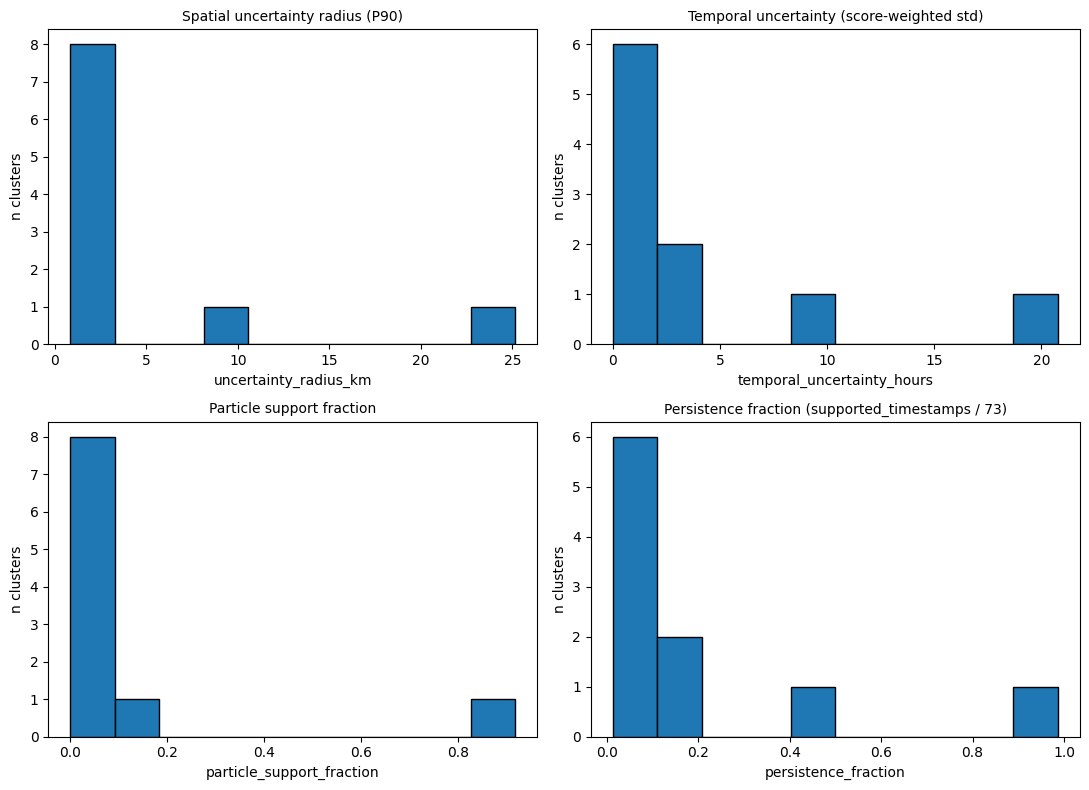

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

vals = [r.uncertainty_radius_km for r in uncertainty_table if np.isfinite(r.uncertainty_radius_km)]
axes[0, 0].hist(vals, bins=10, edgecolor="black")
axes[0, 0].set_xlabel("uncertainty_radius_km"); axes[0, 0].set_ylabel("n clusters")
axes[0, 0].set_title(f"Spatial uncertainty radius (P{DEFAULT_SPATIAL_PERCENTILE:.0f})", fontsize=10)

vals = [r.temporal_uncertainty_hours for r in uncertainty_table]
axes[0, 1].hist(vals, bins=10, edgecolor="black")
axes[0, 1].set_xlabel("temporal_uncertainty_hours"); axes[0, 1].set_ylabel("n clusters")
axes[0, 1].set_title("Temporal uncertainty (score-weighted std)", fontsize=10)

vals = [r.particle_support_fraction for r in uncertainty_table]
axes[1, 0].hist(vals, bins=10, edgecolor="black")
axes[1, 0].set_xlabel("particle_support_fraction"); axes[1, 0].set_ylabel("n clusters")
axes[1, 0].set_title("Particle support fraction", fontsize=10)

vals = [r.persistence_fraction for r in uncertainty_table]
axes[1, 1].hist(vals, bins=10, edgecolor="black")
axes[1, 1].set_xlabel("persistence_fraction"); axes[1, 1].set_ylabel("n clusters")
axes[1, 1].set_title("Persistence fraction (supported_timestamps / 73)", fontsize=10)

fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T38_uncertainty_distributions.png"), dpi=100)
plt.show()

## 10. Bootstrap stability distribution

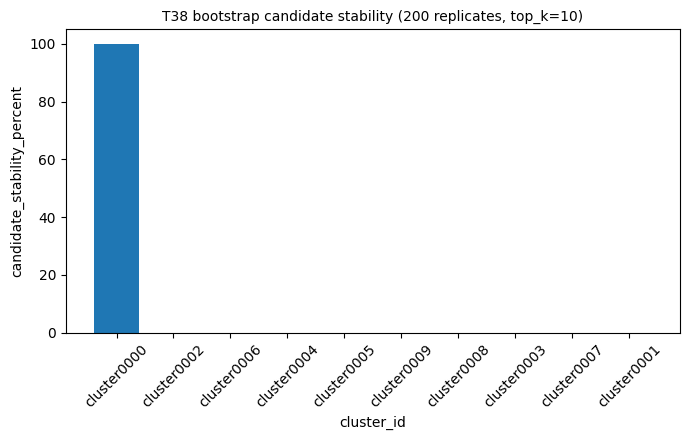

In [13]:
vals = [r.candidate_stability_percent for r in uncertainty_table if r.candidate_stability_percent is not None]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar([r.cluster_id for r in uncertainty_table], [r.candidate_stability_percent or 0.0 for r in uncertainty_table])
ax.set_xlabel("cluster_id"); ax.set_ylabel("candidate_stability_percent")
ax.set_title(f"T38 bootstrap candidate stability ({bootstrap_config.n_replicates} replicates, top_k={bootstrap_config.top_k})", fontsize=10)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T38_bootstrap_stability.png"), dpi=100)
plt.show()

## 11. Part F -- age / particle-spread vs uncertainty diagnostic (honest, not tuned)

In [14]:
age_diag = diagnose_uncertainty_vs_age(clusters, uncertainty_table, all_candidates, t_obs)
print(f"n_clusters = {age_diag.n_clusters}")
print(f"pearson(age_hours, uncertainty_radius_km)  = {age_diag.pearson_age_vs_uncertainty_radius:.4f}")
print(f"spearman(age_hours, uncertainty_radius_km) = {age_diag.spearman_age_vs_uncertainty_radius:.4f}")
print(f"pearson(age_hours, temporal_uncertainty_hours)  = {age_diag.pearson_age_vs_temporal_uncertainty:.4f}")
print(f"spearman(age_hours, temporal_uncertainty_hours) = {age_diag.spearman_age_vs_temporal_uncertainty:.4f}")
print(f"pearson(mean_particle_spread_km, uncertainty_radius_km)  = {age_diag.pearson_spread_vs_uncertainty_radius:.4f}")
print(f"spearman(mean_particle_spread_km, uncertainty_radius_km) = {age_diag.spearman_spread_vs_uncertainty_radius:.4f}")

diag_df = pd.DataFrame(dict(
    cluster_id=[cl.cluster_id for cl in clusters],
    age_hours=age_diag.age_hours,
    mean_particle_spread_km=[round(v, 3) for v in age_diag.mean_particle_spread_km],
    uncertainty_radius_km=[round(v, 3) for v in age_diag.uncertainty_radius_km],
    temporal_uncertainty_hours=[round(v, 2) for v in age_diag.temporal_uncertainty_hours],
))
print(diag_df.to_string(index=False))

n_clusters = 10
pearson(age_hours, uncertainty_radius_km)  = 0.4141
spearman(age_hours, uncertainty_radius_km) = 0.4545
pearson(age_hours, temporal_uncertainty_hours)  = 0.4397
spearman(age_hours, temporal_uncertainty_hours) = 0.4788
pearson(mean_particle_spread_km, uncertainty_radius_km)  = 0.9985
spearman(mean_particle_spread_km, uncertainty_radius_km) = 0.9636
 cluster_id  age_hours  mean_particle_spread_km  uncertainty_radius_km  temporal_uncertainty_hours
cluster0000       72.0                   22.228                 25.157                       20.76
cluster0002       72.0                    6.756                  8.423                        9.01
cluster0006       72.0                    1.389                  2.625                        4.15
cluster0004       53.0                    0.636                  0.843                        0.00
cluster0005       55.0                    0.740                  0.957                        0.00
cluster0009       72.0                  

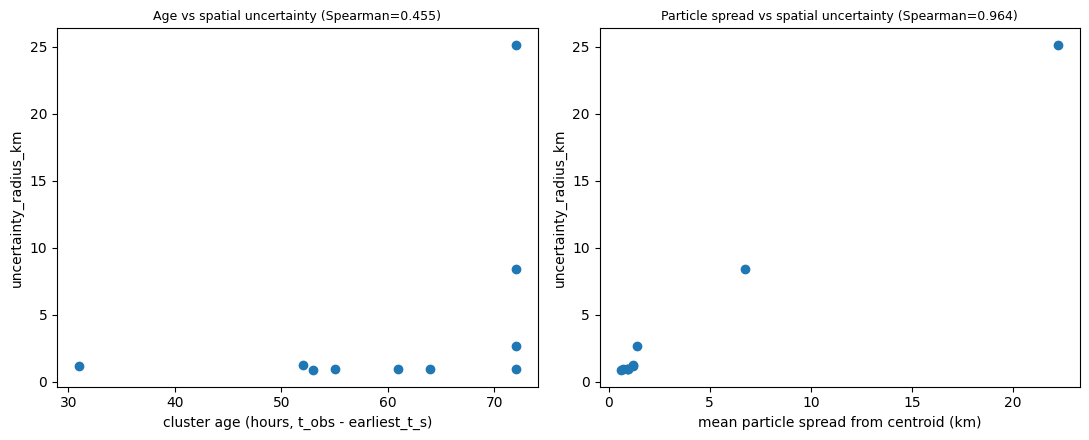

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(age_diag.age_hours, age_diag.uncertainty_radius_km)
axes[0].set_xlabel("cluster age (hours, t_obs - earliest_t_s)"); axes[0].set_ylabel("uncertainty_radius_km")
axes[0].set_title(f"Age vs spatial uncertainty (Spearman={age_diag.spearman_age_vs_uncertainty_radius:.3f})", fontsize=9)
axes[1].scatter(age_diag.mean_particle_spread_km, age_diag.uncertainty_radius_km)
axes[1].set_xlabel("mean particle spread from centroid (km)"); axes[1].set_ylabel("uncertainty_radius_km")
axes[1].set_title(f"Particle spread vs spatial uncertainty (Spearman={age_diag.spearman_spread_vs_uncertainty_radius:.3f})", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T38_age_vs_uncertainty_diagnostic.png"), dpi=100)
plt.show()

**Honest reading of the diagnostic above (whatever the numbers turn out to be on this
run): this is a descriptive correlation over only
`len(clusters)` real clusters -- a small sample. The correlation sign/strength is
reported as-is; the uncertainty formulas in `iste/phase3_uncertainty.py` were NOT
adjusted to produce a particular trend, regardless of what Section 11 shows.**

## 12. Dominant T37 cluster -- spatial extent + uncertainty representation

dominant cluster: cluster0000, n_members=147, spatial_radius_km=24.44, uncertainty_radius_km=25.16


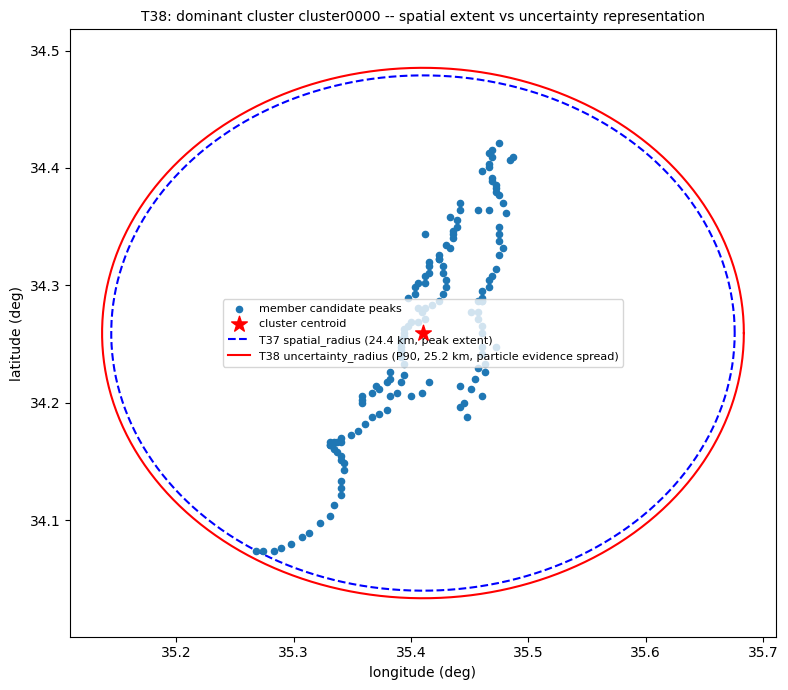

In [16]:
dominant = max(clusters, key=lambda cl: cl.n_members)
dominant_row = next(r for r in uncertainty_table if r.cluster_id == dominant.cluster_id)
print(f"dominant cluster: {dominant.cluster_id}, n_members={dominant.n_members}, "
      f"spatial_radius_km={dominant_row.spatial_radius_km:.2f}, "
      f"uncertainty_radius_km={dominant_row.uncertainty_radius_km:.2f}")

member_ids = set(dominant.member_candidate_ids)
member_cands = [c for c in all_candidates if c.candidate_id in member_ids]

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter([c.x_peak for c in member_cands], [c.y_peak for c in member_cands],
           s=20, c="tab:blue", label="member candidate peaks", zorder=5)
ax.scatter([dominant.centroid_lon], [dominant.centroid_lat], s=140, marker="*", c="red",
           label="cluster centroid", zorder=6)

theta = np.linspace(0, 2 * np.pi, 200)
from iste.kdtree_neighborhood import project_to_local_metres
def _circle_lonlat(radius_m, lat_ref, lon_ref):
    x_m = radius_m * np.cos(theta); y_m = radius_m * np.sin(theta)
    dlat = y_m / 111320.0
    dlon = x_m / (111320.0 * np.cos(np.radians(lat_ref)))
    return lon_ref + dlon, lat_ref + dlat

lon_c, lat_c = _circle_lonlat(dominant.spatial_radius_m, dominant.centroid_lat, dominant.centroid_lon)
ax.plot(lon_c, lat_c, "b--", linewidth=1.5, label=f"T37 spatial_radius ({dominant.spatial_radius_m/1000:.1f} km, peak extent)")

lon_u, lat_u = _circle_lonlat(dominant_row.uncertainty_radius_km * 1000.0, dominant.centroid_lat, dominant.centroid_lon)
ax.plot(lon_u, lat_u, "r-", linewidth=1.5, label=f"T38 uncertainty_radius (P{DEFAULT_SPATIAL_PERCENTILE:.0f}, {dominant_row.uncertainty_radius_km:.1f} km, particle evidence spread)")

ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
ax.set_title(f"T38: dominant cluster {dominant.cluster_id} -- spatial extent vs uncertainty representation", fontsize=10)
ax.legend(fontsize=8, loc="best")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
fig.savefig(os.path.join(REPO_ROOT, "results", "actual_data", "T38_dominant_cluster_uncertainty.png"), dpi=100)
plt.show()

## T37 DBSCAN chaining caveat (must be read together with the plot above)

The dominant cluster above (`cluster0000` on a typical run) spans up to ~24 km because
T37's DBSCAN (`eps_m=2000.0`, `min_samples=1`) TRANSITIVELY chains a slowly-drifting
71-hour trajectory into one nominal "cluster": each hourly step is individually under
`eps_m`, but the chain of ~72 such steps spans much farther overall. This is a
drift CORRIDOR, not a compact source region -- it was flagged in T37's own review and
is repeated here because it directly affects how T38's own numbers must be read:

- `spatial_radius_m`/`spatial_radius_km` (T37) is the geometric extent of this whole
  corridor's candidate PEAK positions -- large, by construction, for a chained cluster.
- `uncertainty_radius_km` (T38, Part C) measures the spread of the PARTICLE EVIDENCE
  pooled from every member candidate along that same corridor -- it is **not**
  artificially shrunk to look more like a compact "source" just because the cluster has
  a single centroid; if the corridor is wide, the pooled-particle evidence legitimately
  spans that same width, and `uncertainty_radius_km` reflects that honestly.
- `candidate_stability_percent` for this cluster reflects how often ANY of its ~147
  member candidates (spanning the whole corridor) lands in the bootstrap top-K -- a
  high value here is evidence that SOME point along this corridor is consistently
  ranked highly under resampling, not evidence that the corridor is a single compact
  source point.

None of T38's uncertainty parameters were adjusted to make this cluster's numbers look
smaller/more "source-like" than the underlying geometry actually is.

## Known limitations (T38 scope only)

- `DEFAULT_TOTAL_TIMESTAMPS=73` reuses T27's own default analysis-grid length
  (`window_hours=72.0`, `interval_hours=1.0`); a caller using a different window must
  pass the matching `total_timestamps` explicitly.
- `DEFAULT_SPATIAL_PERCENTILE=90.0` is an explicit PROTOTYPE/CONFIGURATION choice, not a
  scientifically validated percentile -- fully overridable.
- The bootstrap (Part E) tests stability of the T29/T34 support/density evidence
  specifically under particle-resampling variability; T31/T32/T33/T35 evidence is held
  fixed per replicate (recomputing those from scratch per replicate would require the
  same expensive whole-grid/whole-population recomputation this task explicitly avoids).
  This narrower scope is stated explicitly, not hidden.
- The T29/T34 normalization reference value is not re-derived per replicate; the
  bootstrap scales the already-computed `screening_score` by the bootstrap/original raw
  support ratio (algebraically exact given T34's own formula), rather than rebuilding
  the whole-grid percentile from scratch.
- `candidate_stability_percent` is reported as `None` ("unavailable"), never `0.0`,
  whenever bootstrap was not run.
- The Part F age/spread diagnostic is computed over as few as 10 real clusters -- a
  small sample; its correlation values should not be over-interpreted.
- No T14-T37 module was modified; T36 `source_score` values and T37 cluster
  IDs/membership are confirmed unchanged in Section 6 above.